# 02 - Baseline Modeling and Uncertainty-Aware Validation

This notebook establishes the reproducible machine learning baseline for the
Diabetes 130-US Hospitals dataset and performs the first uncertainty-aware
validation experiment.

## Purpose

The notebook:

1. Loads the audited dataset.
2. Defines the three-class `readmitted` prediction task.
3. Removes identifier variables from model predictors.
4. Uses a patient-level group split to prevent the same patient from appearing
   in both training and test sets.
5. Verifies that there is no patient-level leakage.
6. Builds a reproducible preprocessing pipeline.
7. Trains Logistic Regression and Random Forest baseline models.
8. Evaluates predictive performance.
9. Calculates prediction confidence and uncertainty.
10. Introduces controlled missingness into important features on the held-out
    test set.
11. Compares model performance and uncertainty before and after missingness.
12. Tests whether higher uncertainty is associated with prediction errors.
13. Performs a bootstrap analysis for uncertainty estimates and paired
    differences.
14. Saves baseline and uncertainty-aware results for later analysis.

## Research Question

> Does a model's predictive uncertainty increase when important information is
> missing from an EHR record, and can that uncertainty help identify predictions
> that are less reliable?

The patient-level split is used for the final validation experiment because
multiple encounters can belong to the same patient. The patient identifier is
never used as a model predictor; it is used only to ensure that all encounters
from a patient remain in the same split.

In [23]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    brier_score_loss,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [24]:
from pathlib import Path

# Resolve the repository root from the notebook location.
# This works when the notebook is run from notebooks/ in the repo.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "diabetic_data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Place diabetic_data.csv in data/raw/."
    )

df_raw = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_raw.shape)
print("Dataset path:", DATA_PATH)

print("\nRequired columns:")
for col in ["encounter_id", "patient_nbr", "readmitted"]:
    print(f"{col}: {col in df_raw.columns}")

print("\nUnique patients:", df_raw["patient_nbr"].nunique())
print("\nTarget distribution:")
print(df_raw["readmitted"].value_counts())


Dataset shape: (101766, 50)
Dataset path: /Users/anshulraghu/Desktop/ehr-uncertainty/data/raw/diabetic_data.csv

Required columns:
encounter_id: True
patient_nbr: True
readmitted: True

Unique patients: 71518

Target distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [25]:
# Confirm that the expected raw UCI structure is present.
required_columns = ["encounter_id", "patient_nbr", "readmitted"]
missing_columns = [c for c in required_columns if c not in df_raw.columns]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}. "
        "Use the original UCI Diabetes 130-US Hospitals CSV."
    )

print("PASS: Required identifiers and target are present.")
print("Unique encounters:", df_raw["encounter_id"].nunique())
print("Unique patients:", df_raw["patient_nbr"].nunique())


PASS: Required identifiers and target are present.
Unique encounters: 101766
Unique patients: 71518


In [26]:
# Basic raw-data integrity checks.
print("Missing values in key columns:")
display(df_raw[["encounter_id", "patient_nbr", "readmitted"]].isna().sum())

print("\nDuplicate encounter IDs:", df_raw["encounter_id"].duplicated().sum())
print("Duplicate patient IDs:", df_raw["patient_nbr"].duplicated().sum())

Missing values in key columns:


encounter_id    0
patient_nbr     0
readmitted      0
dtype: int64


Duplicate encounter IDs: 0
Duplicate patient IDs: 30248


In [27]:
# Verify the raw dataset size and target before modeling.
print("Dataset shape:", df_raw.shape)
print("Expected original UCI row count: 101766")
print("Row-count check:", df_raw.shape[0] == 101766)

Dataset shape: (101766, 50)
Expected original UCI row count: 101766
Row-count check: True


In [28]:
print("Dataset shape:", df_raw.shape)

print("\nTarget distribution:")

target_distribution = (
    df_raw["readmitted"]
    .value_counts()
    .rename_axis("readmitted")
    .reset_index(name="count")
)

display(target_distribution)

print("\nTarget proportions:")

target_proportions = (
    df_raw["readmitted"]
    .value_counts(normalize=True)
    .round(4)
    .rename_axis("readmitted")
    .reset_index(name="proportion")
)

display(target_proportions)

Dataset shape: (101766, 50)

Target distribution:


,readmitted,count
0,NO,54864
1,>30,35545
2,<30,11357



Target proportions:


,readmitted,proportion
0,NO,0.5391
1,>30,0.3493
2,<30,0.1116


## 1. Define the Prediction Task

The target is the three-class `readmitted` variable:

- `NO` — the patient was not readmitted within 30 days
- `>30` — the patient was readmitted after 30 days
- `<30` — the patient was readmitted within 30 days

The task is treated as a three-class classification problem.

The identifiers `encounter_id` and `patient_nbr` are excluded from model predictors. However, `patient_nbr` is retained separately as a grouping variable so that encounters belonging to the same patient cannot be split across the training and test sets.

In [29]:
TARGET = "readmitted"

IDENTIFIER_COLUMNS = [
    "encounter_id",
    "patient_nbr",
]

# Model features: remove target and identifiers
X = df_raw.drop(
    columns=[TARGET] + IDENTIFIER_COLUMNS
).copy()

# Target
y = df_raw[TARGET].copy()

# Keep patient ID separately for group-based splitting
groups = df_raw["patient_nbr"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("groups shape:", groups.shape)

print("\nPatient IDs:", groups.nunique())
print("Target classes:", y.unique())

X shape: (101766, 47)
y shape: (101766,)
groups shape: (101766,)

Patient IDs: 71518
Target classes: ['NO' '>30' '<30']


In [30]:
print("df_raw shape:", df_raw.shape)

print("\nColumns in df_raw:")
print(df_raw.columns.tolist())

print("\nChecking required columns:")
for col in ["encounter_id", "patient_nbr", "readmitted"]:
    print(f"{col}: {col in df_raw.columns}")

df_raw shape: (101766, 50)

Columns in df_raw:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Checking required columns:
encounter_id: True
patient_nbr: True
readmitted: True


In [31]:
duplicate_count = X.duplicated().sum()

print(f"Duplicate predictor rows: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_count / len(X) * 100:.2f}%")

Duplicate predictor rows: 0
Duplicate percentage: 0.00%


## 2. Patient-Level Train/Test Split

A patient-level split is used for the final validation experiment.

A normal row-level split can place different encounters from the same patient into both training and test sets. This can make evaluation overly optimistic because the model is evaluated on a patient whose other encounters were already available during training.

`patient_nbr` is therefore used as the grouping variable:

- all encounters from one patient remain in one split;
- `patient_nbr` is never used as a model feature;
- the test set contains patients not present in the training set.

In [32]:
print(df_raw.columns.tolist())
print(df_raw.head())

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']
   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)      ?   
1        149190     55629189        

In [33]:
from sklearn.model_selection import GroupShuffleSplit

# IMPORTANT:
# Use df_raw for patient IDs.
# df_raw must be the original 48-column dataset.
groups = df_raw["patient_nbr"].copy()

# X and y should already have been created from df_raw
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nUnique patients:")
print("Train:", groups_train.nunique())
print("Test:", groups_test.nunique())

# Critical leakage check
train_patients = set(groups_train)
test_patients = set(groups_test)

print("\nShared patients:", len(train_patients.intersection(test_patients)))

assert len(train_patients.intersection(test_patients)) == 0

print("✓ Patient-level leakage check passed.")

Train shape: (81613, 47)
Test shape: (20153, 47)

Unique patients:
Train: 57214
Test: 14304

Shared patients: 0
✓ Patient-level leakage check passed.


In [34]:
train_patients = set(groups_train)
test_patients = set(groups_test)

overlap = train_patients.intersection(test_patients)

print("Patient-level leakage check")
print("=" * 40)
print("Unique training patients:", len(train_patients))
print("Unique test patients:    ", len(test_patients))
print("Patients in both sets:   ", len(overlap))

assert len(overlap) == 0

print("\nPASS: No patients are shared between train and test.")

Patient-level leakage check
Unique training patients: 57214
Unique test patients:     14304
Patients in both sets:    0

PASS: No patients are shared between train and test.


In [35]:
train_rows = set(X_train.index)
test_rows = set(X_test.index)

row_overlap = train_rows.intersection(test_rows)

print("Row-level overlap:", len(row_overlap))

assert len(row_overlap) == 0

print("PASS: No observations are shared between train and test.")

Row-level overlap: 0
PASS: No observations are shared between train and test.


## 3. Preprocessing

The baseline uses separate preprocessing for numerical and categorical
variables.

### Numerical variables

Missing numerical values are replaced using the median calculated from the
training data.

Numerical features are standardized for Logistic Regression.

### Categorical variables

Missing categorical values are replaced with the most frequent category.

Categorical variables are one-hot encoded.

All preprocessing is placed inside scikit-learn pipelines so that preprocessing
parameters are learned from the training data rather than from the held-out
test set.

In [36]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print(f"Numeric features:     {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:     11
Categorical features: 36

Numeric features:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features:
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [37]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 4. Baseline Model 1 — Multinomial Logistic Regression

Logistic Regression provides a relatively simple and interpretable baseline.

It also produces class probabilities, which are useful for the later analysis of predictive confidence and uncertainty.

In [38]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                solver="saga",
                random_state=RANDOM_STATE
            ),
        ),
    ]
)

print("Training logistic regression...")

logistic_model.fit(X_train, y_train)

print("Training complete.")

Training logistic regression...
Training complete.


In [39]:
y_pred_logistic = logistic_model.predict(X_test)
y_proba_logistic = logistic_model.predict_proba(X_test)

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

logistic_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred_logistic
)

logistic_macro_f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="macro"
)

logistic_log_loss = log_loss(
    y_test,
    y_proba_logistic,
    labels=logistic_model.classes_
)

print("Logistic Regression Results")
print("=" * 40)
print(f"Accuracy:            {logistic_accuracy:.4f}")
print(f"Balanced Accuracy:   {logistic_balanced_accuracy:.4f}")
print(f"Macro F1:             {logistic_macro_f1:.4f}")
print(f"Log Loss:             {logistic_log_loss:.4f}")

Logistic Regression Results
Accuracy:            0.5865
Balanced Accuracy:   0.4046
Macro F1:             0.3863
Log Loss:             0.8812


In [40]:
print("Classification Report — Logistic Regression")
print()

print(
    classification_report(
        y_test,
        y_pred_logistic,
        digits=4
    )
)

Classification Report — Logistic Regression

              precision    recall  f1-score   support

         <30     0.3088    0.0195    0.0367      2151
         >30     0.5107    0.3419    0.4096      6988
          NO     0.6120    0.8524    0.7125     11014

    accuracy                         0.5865     20153
   macro avg     0.4772    0.4046    0.3863     20153
weighted avg     0.5445    0.5865    0.5353     20153



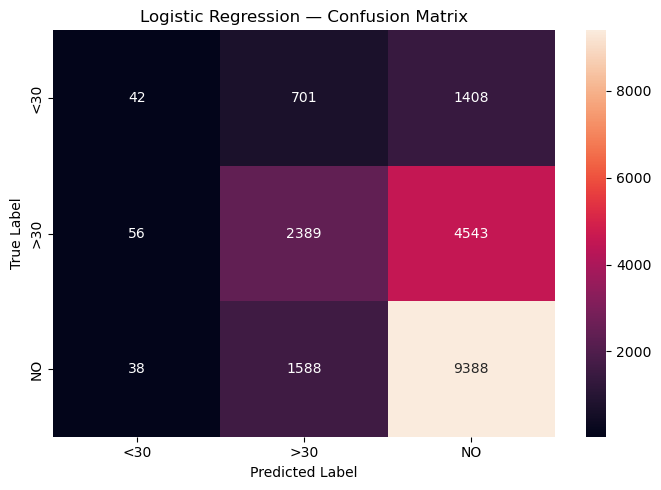

In [41]:
logistic_cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=logistic_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

### Why use multiple metrics?

The target classes are imbalanced, with `NO` representing the largest class.

Therefore, accuracy by itself can hide poor performance on less frequent
classes, particularly the `<30` class.

For this reason, the baseline reports:

- Accuracy
- Balanced accuracy
- Macro F1
- Log loss

Log loss is especially useful for this project because it evaluates the quality
of the model's predicted probabilities, which will become important when
studying predictive uncertainty.

## 5. Baseline Model 2 — Random Forest

A Random Forest provides a second baseline using a nonlinear tree-based model
family.

Comparing Logistic Regression with Random Forest provides a broader baseline
before focusing on uncertainty-aware behavior.

In [42]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                n_jobs=-1,
                class_weight="balanced"
            ),
        ),
    ]
)

print("Training random forest...")

random_forest_model.fit(X_train, y_train)

print("Training complete.")

Training random forest...
Training complete.


In [43]:
y_pred_rf = random_forest_model.predict(X_test)
y_proba_rf = random_forest_model.predict_proba(X_test)

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred_rf
)

rf_macro_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="macro"
)

rf_log_loss = log_loss(
    y_test,
    y_proba_rf,
    labels=random_forest_model.classes_
)

print("Random Forest Results")
print("=" * 40)
print(f"Accuracy:            {rf_accuracy:.4f}")
print(f"Balanced Accuracy:   {rf_balanced_accuracy:.4f}")
print(f"Macro F1:             {rf_macro_f1:.4f}")
print(f"Log Loss:             {rf_log_loss:.4f}")

Random Forest Results
Accuracy:            0.5916
Balanced Accuracy:   0.3993
Macro F1:             0.3723
Log Loss:             0.8760


In [44]:
print("Classification Report — Random Forest")
print()

print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=4
    )
)

Classification Report — Random Forest

              precision    recall  f1-score   support

         <30     0.6667    0.0037    0.0074      2151
         >30     0.5260    0.3074    0.3880      6988
          NO     0.6083    0.8868    0.7216     11014

    accuracy                         0.5916     20153
   macro avg     0.6003    0.3993    0.3723     20153
weighted avg     0.5860    0.5916    0.5297     20153



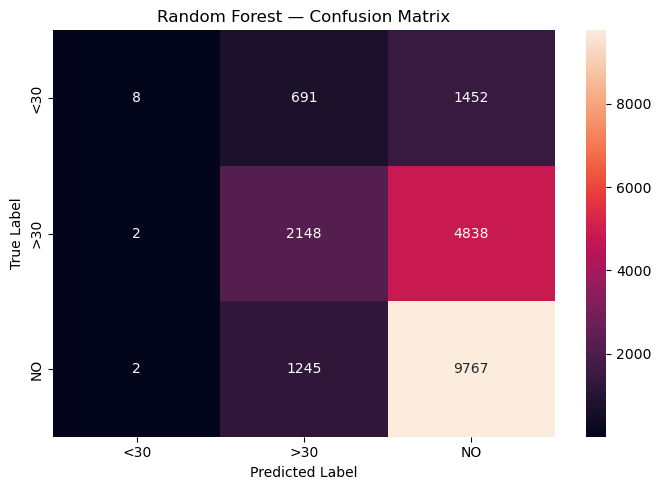

In [45]:
rf_cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=random_forest_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    xticklabels=random_forest_model.classes_,
    yticklabels=random_forest_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

In [46]:
results = pd.DataFrame(
    {
        "Model": [
            "Logistic Regression",
            "Random Forest",
        ],
        "Accuracy": [
            logistic_accuracy,
            rf_accuracy,
        ],
        "Balanced Accuracy": [
            logistic_balanced_accuracy,
            rf_balanced_accuracy,
        ],
        "Macro F1": [
            logistic_macro_f1,
            rf_macro_f1,
        ],
        "Log Loss": [
            logistic_log_loss,
            rf_log_loss,
        ],
    }
)

results = results.round(4)

display(results)

,Model,Accuracy,Balanced Accuracy,Macro F1,Log Loss
0,Logistic Regression,0.5865,0.4046,0.3863,0.8812
1,Random Forest,0.5916,0.3993,0.3723,0.8760


## 6. Baseline Predictive Confidence

For the Logistic Regression model, confidence is defined as the maximum predicted class probability:

`confidence = max(P(class | x))`

A corresponding simple uncertainty score is:

`uncertainty = 1 - confidence`

This is an initial operational measure of predictive uncertainty. It is not being treated as a fully calibrated uncertainty estimate.

In [47]:
probability_df = pd.DataFrame(
    y_proba_logistic,
    columns=[
        f"prob_{class_name}"
        for class_name in logistic_model.classes_
    ],
    index=y_test.index
)

probability_df["true_label"] = y_test
probability_df["predicted_label"] = y_pred_logistic

probability_columns = [
    f"prob_{class_name}"
    for class_name in logistic_model.classes_
]

probability_df["confidence"] = probability_df[
    probability_columns
].max(axis=1)

probability_df["uncertainty"] = (
    1 - probability_df["confidence"]
)

probability_df["correct"] = (
    probability_df["true_label"]
    == probability_df["predicted_label"]
)

display(probability_df.head(10))

,prob_<30,prob_>30,prob_NO,true_label,predicted_label,confidence,uncertainty,correct
13,0.150078,0.397393,0.452529,NO,NO,0.452529,0.547471,True
22,0.098810,0.222672,0.678518,NO,NO,0.678518,0.321482,True
30,0.125680,0.491981,0.382339,NO,>30,0.491981,0.508019,False
32,0.061930,0.309903,0.628167,>30,NO,0.628167,0.371833,False
39,0.099781,0.555182,0.345037,>30,>30,0.555182,0.444818,True
43,0.074022,0.410555,0.515422,>30,NO,0.515422,0.484578,False
45,0.124077,0.190836,0.685087,NO,NO,0.685087,0.314913,True
46,0.215078,0.521126,0.263796,<30,>30,0.521126,0.478874,False
48,0.095107,0.372948,0.531945,NO,NO,0.531945,0.468055,True
50,0.091761,0.167010,0.741228,<30,NO,0.741228,0.258772,False


In [48]:
print("Confidence summary:")
display(
    probability_df["confidence"].describe()
)

print("\nUncertainty summary:")
display(
    probability_df["uncertainty"].describe()
)

print("\nAverage confidence by prediction correctness:")

display(
    probability_df.groupby("correct")["confidence"]
    .agg(["mean", "median", "count"])
)

print("\nAverage uncertainty by prediction correctness:")

display(
    probability_df.groupby("correct")["uncertainty"]
    .agg(["mean", "median", "count"])
)

Confidence summary:


count    20153.000000
mean         0.589851
std          0.109300
min          0.335844
25%          0.503254
50%          0.575541
75%          0.663336
max          0.976801
Name: confidence, dtype: float64


Uncertainty summary:


count    20153.000000
mean         0.410149
std          0.109300
min          0.023199
25%          0.336664
50%          0.424459
75%          0.496746
max          0.664156
Name: uncertainty, dtype: float64


Average confidence by prediction correctness:


,mean,median,count
correct,,,
False,0.561724,0.545455,8334
True,0.609684,0.599191,11819



Average uncertainty by prediction correctness:


,mean,median,count
correct,,,
False,0.438276,0.454545,8334
True,0.390316,0.400809,11819


In [49]:
most_uncertain = (
    probability_df
    .sort_values("confidence")
    .head(10)
)

display(most_uncertain)

,prob_<30,prob_>30,prob_NO,true_label,predicted_label,confidence,uncertainty,correct
31786,0.328939,0.335217,0.335844,NO,NO,0.335844,0.664156,True
8533,0.336500,0.327612,0.335887,>30,<30,0.336500,0.663500,False
67692,0.327065,0.336169,0.336767,<30,NO,0.336767,0.663233,False
5935,0.341185,0.339450,0.319366,>30,<30,0.341185,0.658815,False
16024,0.341397,0.318371,0.340231,NO,<30,0.341397,0.658603,False
49960,0.315262,0.342500,0.342238,>30,>30,0.342500,0.657500,True
101062,0.321146,0.335152,0.343703,>30,NO,0.343703,0.656297,False
57522,0.343962,0.312771,0.343267,NO,<30,0.343962,0.656038,False
51081,0.345375,0.319124,0.335500,>30,<30,0.345375,0.654625,False
18082,0.342417,0.312071,0.345512,NO,NO,0.345512,0.654488,True


## 7. Controlled Missingness Experiment

The main research question concerns whether uncertainty increases when important information is missing.

The experiment therefore keeps the same held-out test observations and creates a second version of the test set with controlled additional missingness.

The model is **not retrained** on the modified test set.

This produces a paired comparison:

- Original held-out test observations
- The same observations after controlled missingness

This makes it possible to examine whether missing information changes performance and predictive uncertainty.

In [50]:
# Features selected for the first controlled missingness experiment. These are based on the feature-importance analysis already performed in the project 

IMPORTANT_FEATURES = [
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code",
]

IMPORTANT_FEATURES = [
    feature
    for feature in IMPORTANT_FEATURES
    if feature in X_test.columns
]

print("Features selected for controlled missingness:")
for feature in IMPORTANT_FEATURES:
    print(f"  - {feature}")

assert len(IMPORTANT_FEATURES) > 0

Features selected for controlled missingness:
  - weight
  - max_glu_serum
  - A1Cresult
  - medical_specialty
  - payer_code


In [51]:
def introduce_missingness(
    X,
    columns,
    missing_rate=0.20,
    random_state=42
):
    """
    Introduce controlled random missingness into selected columns.

    The original dataframe is copied, so the original held-out test set
    remains unchanged.
    """

    X_missing = X.copy()

    rng = np.random.default_rng(random_state)

    for column in columns:
        mask = rng.random(len(X_missing)) < missing_rate
        X_missing.loc[mask, column] = np.nan

    return X_missing

In [52]:
MISSINGNESS_RATE = 0.20

X_test_original = X_test.copy()

X_test_missing = introduce_missingness(
    X_test_original,
    columns=IMPORTANT_FEATURES,
    missing_rate=MISSINGNESS_RATE,
    random_state=RANDOM_STATE
)

print(
    f"Controlled missingness rate per selected feature: "
    f"{MISSINGNESS_RATE:.0%}"
)

print("\nMissingness added to selected features:")

missingness_summary = pd.DataFrame(
    {
        "Original Missing Rate": [
            X_test_original[feature].isna().mean()
            for feature in IMPORTANT_FEATURES
        ],
        "New Missing Rate": [
            X_test_missing[feature].isna().mean()
            for feature in IMPORTANT_FEATURES
        ],
    },
    index=IMPORTANT_FEATURES
)

display(missingness_summary.round(4))

Controlled missingness rate per selected feature: 20%

Missingness added to selected features:


,Original Missing Rate,New Missing Rate
weight,0.0000,0.2008
max_glu_serum,0.9507,0.9603
A1Cresult,0.8341,0.8665
medical_specialty,0.0000,0.1952
payer_code,0.0000,0.2002


In [53]:
# Original held-out predictions
y_pred_original = logistic_model.predict(X_test_original)
y_prob_original = logistic_model.predict_proba(X_test_original)

# Predictions after controlled missingness
y_pred_missing = logistic_model.predict(X_test_missing)
y_prob_missing = logistic_model.predict_proba(X_test_missing)

print("Predictions generated for both test conditions.")

Predictions generated for both test conditions.


In [54]:
confidence_original = y_prob_original.max(axis=1)
confidence_missing = y_prob_missing.max(axis=1)

uncertainty_original = 1 - confidence_original
uncertainty_missing = 1 - confidence_missing

errors_original = (
    y_pred_original != y_test.to_numpy()
)

errors_missing = (
    y_pred_missing != y_test.to_numpy()
)

print("Original mean confidence:",
      f"{confidence_original.mean():.4f}")

print("Missing-data mean confidence:",
      f"{confidence_missing.mean():.4f}")

print("\nOriginal mean uncertainty:",
      f"{uncertainty_original.mean():.4f}")

print("Missing-data mean uncertainty:",
      f"{uncertainty_missing.mean():.4f}")

Original mean confidence: 0.5899
Missing-data mean confidence: 0.5846

Original mean uncertainty: 0.4101
Missing-data mean uncertainty: 0.4154


In [55]:
def evaluate_predictions(y_true, y_pred, y_prob, classes):
    return {
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),
        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro"
        ),
        "Log Loss": log_loss(
            y_true,
            y_prob,
            labels=classes
        ),
    }


original_metrics = evaluate_predictions(
    y_test,
    y_pred_original,
    y_prob_original,
    logistic_model.classes_
)

missing_metrics = evaluate_predictions(
    y_test,
    y_pred_missing,
    y_prob_missing,
    logistic_model.classes_
)

missingness_results = pd.DataFrame(
    {
        "Original": original_metrics,
        "20% Controlled Missingness": missing_metrics,
    }
)

missingness_results["Difference"] = (
    missingness_results["20% Controlled Missingness"]
    - missingness_results["Original"]
)

display(missingness_results.round(4))

,Original,20% Controlled Missingness,Difference
Accuracy,0.5865,0.5857,-0.0007
Balanced Accuracy,0.4046,0.4057,0.0011
Macro F1,0.3863,0.3883,0.0020
Log Loss,0.8812,0.8828,0.0016


In [56]:
uncertainty_change = pd.DataFrame(
    {
        "Original Confidence": confidence_original,
        "Missing Confidence": confidence_missing,
        "Original Uncertainty": uncertainty_original,
        "Missing Uncertainty": uncertainty_missing,
        "Confidence Change": (
            confidence_missing - confidence_original
        ),
        "Uncertainty Change": (
            uncertainty_missing - uncertainty_original
        ),
        "Original Correct": ~errors_original,
        "Missing Correct": ~errors_missing,
    },
    index=y_test.index
)

print("Mean uncertainty change:")
print(
    uncertainty_change["Uncertainty Change"].mean()
)

print("\nMedian uncertainty change:")
print(
    uncertainty_change["Uncertainty Change"].median()
)

print("\nMean confidence change:")
print(
    uncertainty_change["Confidence Change"].mean()
)

Mean uncertainty change:
0.00524878918879869

Median uncertainty change:
0.0

Mean confidence change:
-0.00524878918879869


## 8. Does Higher Uncertainty Identify Less Reliable Predictions?

The next analysis tests whether predictions with higher uncertainty are more likely to be incorrect.

If uncertainty is useful for selective prediction, incorrect predictions should tend to have higher uncertainty than correct predictions.

In [57]:
error_uncertainty_summary = pd.DataFrame(
    {
        "Correct": [
            (~errors_missing).sum(),
        ],
        "Incorrect": [
            errors_missing.sum(),
        ],
        "Mean Uncertainty — Correct": [
            uncertainty_missing[~errors_missing].mean()
        ],
        "Mean Uncertainty — Incorrect": [
            uncertainty_missing[errors_missing].mean()
        ],
        "Mean Confidence — Correct": [
            confidence_missing[~errors_missing].mean()
        ],
        "Mean Confidence — Incorrect": [
            confidence_missing[errors_missing].mean()
        ],
    }
)

display(error_uncertainty_summary.round(4))

,Correct,Incorrect,Mean Uncertainty — Correct,Mean Uncertainty — Incorrect,Mean Confidence — Correct,Mean Confidence — Incorrect
0,11804,8349,0.3962,0.4425,0.6038,0.5575


In [58]:
uncertainty_analysis = pd.DataFrame(
    {
        "uncertainty": uncertainty_missing,
        "error": errors_missing.astype(int),
    },
    index=y_test.index
)

uncertainty_analysis["uncertainty_quartile"] = pd.qcut(
    uncertainty_analysis["uncertainty"],
    q=4,
    duplicates="drop"
)

quartile_summary = (
    uncertainty_analysis
    .groupby(
        "uncertainty_quartile",
        observed=True
    )
    .agg(
        mean_uncertainty=("uncertainty", "mean"),
        error_rate=("error", "mean"),
        count=("error", "size"),
    )
    .reset_index()
)

display(quartile_summary.round(4))

,uncertainty_quartile,mean_uncertainty,error_rate,count
0,"(0.030600000000000002, 0.345]",0.2677,0.2677,5039
1,"(0.345, 0.43]",0.3887,0.3924,5038
2,"(0.43, 0.5]",0.4660,0.4637,5038
3,"(0.5, 0.664]",0.5392,0.5333,5038


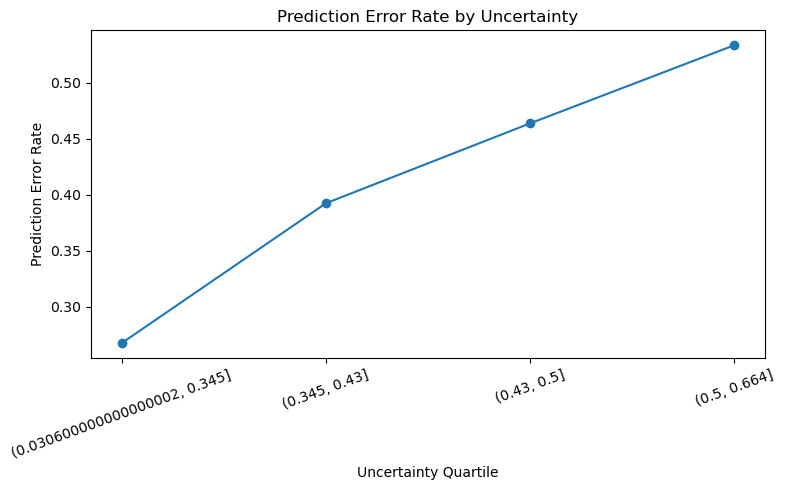

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(len(quartile_summary)),
    quartile_summary["error_rate"],
    marker="o"
)

plt.xticks(
    range(len(quartile_summary)),
    [
        str(interval)
        for interval in quartile_summary["uncertainty_quartile"]
    ],
    rotation=20
)

plt.xlabel("Uncertainty Quartile")
plt.ylabel("Prediction Error Rate")
plt.title("Prediction Error Rate by Uncertainty")
plt.tight_layout()
plt.show()

## 9. Bootstrap Confidence Intervals

The final validation requires uncertainty around reported metrics.

Because multiple encounters can belong to the same patient, the bootstrap resamples patients rather than individual encounters.

This preserves the patient-level grouping structure during resampling.

The analysis reports 95% bootstrap confidence intervals for:

- balanced accuracy;
- macro F1;
- log loss;
- mean uncertainty;
- the paired difference in uncertainty between the original and
  missing-information conditions.

In [60]:
def patient_level_bootstrap(
    y_true,
    y_pred_original,
    y_pred_missing,
    y_prob_original,
    y_prob_missing,
    uncertainty_original,
    uncertainty_missing,
    patient_groups,
    n_bootstrap=1000,
    random_state=42,
):
    """
    Patient-level bootstrap.

    Entire patients are resampled as groups so that multiple encounters from
    the same patient stay together within each bootstrap sample.
    """

    rng = np.random.default_rng(random_state)

    patient_groups = np.asarray(patient_groups)
    unique_patients = np.unique(patient_groups)

    patient_to_indices = {
        patient: np.where(patient_groups == patient)[0]
        for patient in unique_patients
    }

    bootstrap_results = []

    for _ in range(n_bootstrap):

        sampled_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        sampled_indices = np.concatenate(
            [
                patient_to_indices[patient]
                for patient in sampled_patients
            ]
        )

        y_b = np.asarray(y_true)[sampled_indices]

        pred_orig_b = np.asarray(
            y_pred_original
        )[sampled_indices]

        pred_missing_b = np.asarray(
            y_pred_missing
        )[sampled_indices]

        prob_orig_b = np.asarray(
            y_prob_original
        )[sampled_indices]

        prob_missing_b = np.asarray(
            y_prob_missing
        )[sampled_indices]

        uncertainty_orig_b = np.asarray(
            uncertainty_original
        )[sampled_indices]

        uncertainty_missing_b = np.asarray(
            uncertainty_missing
        )[sampled_indices]

        balanced_orig = balanced_accuracy_score(
            y_b,
            pred_orig_b
        )

        balanced_missing = balanced_accuracy_score(
            y_b,
            pred_missing_b
        )

        f1_orig = f1_score(
            y_b,
            pred_orig_b,
            average="macro"
        )

        f1_missing = f1_score(
            y_b,
            pred_missing_b,
            average="macro"
        )

        logloss_orig = log_loss(
            y_b,
            prob_orig_b,
            labels=logistic_model.classes_
        )

        logloss_missing = log_loss(
            y_b,
            prob_missing_b,
            labels=logistic_model.classes_
        )

        mean_uncertainty_orig = (
            uncertainty_orig_b.mean()
        )

        mean_uncertainty_missing = (
            uncertainty_missing_b.mean()
        )

        bootstrap_results.append(
            {
                "balanced_accuracy_original": balanced_orig,
                "balanced_accuracy_missing": balanced_missing,
                "balanced_accuracy_difference": (
                    balanced_missing - balanced_orig
                ),
                "macro_f1_original": f1_orig,
                "macro_f1_missing": f1_missing,
                "macro_f1_difference": (
                    f1_missing - f1_orig
                ),
                "log_loss_original": logloss_orig,
                "log_loss_missing": logloss_missing,
                "log_loss_difference": (
                    logloss_missing - logloss_orig
                ),
                "mean_uncertainty_original": (
                    mean_uncertainty_orig
                ),
                "mean_uncertainty_missing": (
                    mean_uncertainty_missing
                ),
                "uncertainty_difference": (
                    mean_uncertainty_missing
                    - mean_uncertainty_orig
                ),
            }
        )

    return pd.DataFrame(bootstrap_results)

In [61]:
N_BOOTSTRAP = 1000

bootstrap_results = patient_level_bootstrap(
    y_true=y_test,
    y_pred_original=y_pred_original,
    y_pred_missing=y_pred_missing,
    y_prob_original=y_prob_original,
    y_prob_missing=y_prob_missing,
    uncertainty_original=uncertainty_original,
    uncertainty_missing=uncertainty_missing,
    patient_groups=groups_test.to_numpy(),
    n_bootstrap=N_BOOTSTRAP,
    random_state=RANDOM_STATE,
)

print(
    f"Completed {len(bootstrap_results):,} "
    "patient-level bootstrap samples."
)

display(bootstrap_results.head())

Completed 1,000 patient-level bootstrap samples.


,balanced_accuracy_original,balanced_accuracy_missing,balanced_accuracy_difference,macro_f1_original,macro_f1_missing,macro_f1_difference,log_loss_original,log_loss_missing,log_loss_difference,mean_uncertainty_original,mean_uncertainty_missing,uncertainty_difference
0,0.407618,0.408597,0.000979,0.390277,0.391898,0.001621,0.876739,0.878199,0.001460,0.410903,0.416236,0.005333
1,0.407766,0.408697,0.000931,0.388571,0.390336,0.001765,0.874719,0.875895,0.001176,0.408625,0.414030,0.005406
2,0.402542,0.403848,0.001306,0.383351,0.385786,0.002435,0.888878,0.890329,0.001451,0.411102,0.416515,0.005413
3,0.405954,0.406110,0.000157,0.388007,0.389288,0.001281,0.885870,0.887592,0.001722,0.411039,0.416582,0.005543
4,0.405741,0.406854,0.001113,0.388347,0.390533,0.002186,0.881731,0.883697,0.001966,0.410559,0.415782,0.005223


In [62]:
def bootstrap_ci(values, confidence=0.95):
    alpha = 1 - confidence

    lower = np.quantile(
        values,
        alpha / 2
    )

    upper = np.quantile(
        values,
        1 - alpha / 2
    )

    return lower, upper

In [63]:
bootstrap_summary = []

metrics_to_report = {
    "Balanced Accuracy Difference":
        "balanced_accuracy_difference",
    "Macro F1 Difference":
        "macro_f1_difference",
    "Log Loss Difference":
        "log_loss_difference",
    "Mean Uncertainty Difference":
        "uncertainty_difference",
}

for metric_name, column in metrics_to_report.items():

    values = bootstrap_results[column]

    point_estimate = values.mean()

    lower, upper = bootstrap_ci(values)

    bootstrap_summary.append(
        {
            "Metric": metric_name,
            "Point Estimate": point_estimate,
            "95% CI Lower": lower,
            "95% CI Upper": upper,
        }
    )

bootstrap_summary = pd.DataFrame(
    bootstrap_summary
)

display(
    bootstrap_summary.round(4)
)

,Metric,Point Estimate,95% CI Lower,95% CI Upper
0,Balanced Accuracy Difference,0.0011,-0.0002,0.0026
1,Macro F1 Difference,0.0020,0.0005,0.0037
2,Log Loss Difference,0.0016,0.0009,0.0023
3,Mean Uncertainty Difference,0.0053,0.0049,0.0056


In [64]:
uncertainty_diff_values = (
    bootstrap_results["uncertainty_difference"]
)

uncertainty_diff_lower, uncertainty_diff_upper = (
    bootstrap_ci(uncertainty_diff_values)
)

mean_uncertainty_difference = (
    uncertainty_missing.mean()
    - uncertainty_original.mean()
)

print("Mean uncertainty difference:")
print(
    f"{mean_uncertainty_difference:.4f}"
)

print("\n95% bootstrap CI:")
print(
    f"[{uncertainty_diff_lower:.4f}, "
    f"{uncertainty_diff_upper:.4f}]"
)

if uncertainty_diff_lower > 0:
    print(
        "\nInterpretation: The 95% CI is entirely above zero. "
        "The missing-information condition produced higher uncertainty "
        "in this experiment."
    )
elif uncertainty_diff_upper < 0:
    print(
        "\nInterpretation: The 95% CI is entirely below zero. "
        "The missing-information condition produced lower uncertainty "
        "in this experiment."
    )
else:
    print(
        "\nInterpretation: The 95% CI includes zero. "
        "The experiment does not establish a statistically distinguishable "
        "change in uncertainty."
    )

Mean uncertainty difference:
0.0052

95% bootstrap CI:
[0.0049, 0.0056]

Interpretation: The 95% CI is entirely above zero. The missing-information condition produced higher uncertainty in this experiment.


## 10. Calibration and Probability Quality

The maximum predicted probability is used as an initial confidence measure, but confidence alone does not establish calibration.

The multiclass Brier score is therefore calculated as an additional measure of probability quality.

Lower Brier score indicates better probabilistic accuracy.

In [65]:
def multiclass_brier_score(y_true, y_prob, classes):
    """
    Multiclass Brier score using one-hot encoded true labels.
    """

    y_true_array = np.asarray(y_true)

    y_one_hot = np.zeros(
        (len(y_true_array), len(classes))
    )

    for i, class_name in enumerate(classes):
        y_one_hot[:, i] = (
            y_true_array == class_name
        ).astype(float)

    return np.mean(
        np.sum(
            (y_prob - y_one_hot) ** 2,
            axis=1
        )
    )


brier_original = multiclass_brier_score(
    y_test,
    y_prob_original,
    logistic_model.classes_
)

brier_missing = multiclass_brier_score(
    y_test,
    y_prob_missing,
    logistic_model.classes_
)

print("Multiclass Brier Score")
print("=" * 40)
print(f"Original:              {brier_original:.4f}")
print(f"20% Missingness:       {brier_missing:.4f}")
print(
    f"Difference:            "
    f"{brier_missing - brier_original:.4f}"
)

Multiclass Brier Score
Original:              0.5291
20% Missingness:       0.5304
Difference:            0.0012


## 11. Final Validation Results

This table summarizes the paired original-versus-missing-information experiment.

The values are generated from the patient-level held-out test set and should be used as the source for the final README and validation audit.

In [66]:
final_results = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Balanced Accuracy",
            "Macro F1",
            "Log Loss",
            "Mean Confidence",
            "Mean Uncertainty",
            "Multiclass Brier Score",
        ],
        "Original": [
            accuracy_score(
                y_test,
                y_pred_original
            ),
            balanced_accuracy_score(
                y_test,
                y_pred_original
            ),
            f1_score(
                y_test,
                y_pred_original,
                average="macro"
            ),
            log_loss(
                y_test,
                y_prob_original,
                labels=logistic_model.classes_
            ),
            confidence_original.mean(),
            uncertainty_original.mean(),
            brier_original,
        ],
        "20% Missingness": [
            accuracy_score(
                y_test,
                y_pred_missing
            ),
            balanced_accuracy_score(
                y_test,
                y_pred_missing
            ),
            f1_score(
                y_test,
                y_pred_missing,
                average="macro"
            ),
            log_loss(
                y_test,
                y_prob_missing,
                labels=logistic_model.classes_
            ),
            confidence_missing.mean(),
            uncertainty_missing.mean(),
            brier_missing,
        ],
    }
)

final_results["Difference"] = (
    final_results["20% Missingness"]
    - final_results["Original"]
)

display(
    final_results.round(4)
)

,Metric,Original,20% Missingness,Difference
0,Accuracy,0.5865,0.5857,-0.0007
1,Balanced Accuracy,0.4046,0.4057,0.0011
2,Macro F1,0.3863,0.3883,0.0020
3,Log Loss,0.8812,0.8828,0.0016
4,Mean Confidence,0.5899,0.5846,-0.0052
5,Mean Uncertainty,0.4101,0.4154,0.0052
6,Multiclass Brier Score,0.5291,0.5304,0.0012


In [67]:
headline_uncertainty = {
    "Metric": "Mean Uncertainty",
    "Original": uncertainty_original.mean(),
    "Missingness": uncertainty_missing.mean(),
    "Difference": uncertainty_missing.mean()
                  - uncertainty_original.mean(),
    "95% CI Lower": uncertainty_diff_lower,
    "95% CI Upper": uncertainty_diff_upper,
    "Bootstrap Runs": N_BOOTSTRAP,
}

headline_results = pd.DataFrame(
    [headline_uncertainty]
)

display(
    headline_results.round(4)
)

,Metric,Original,Missingness,Difference,95% CI Lower,95% CI Upper,Bootstrap Runs
0,Mean Uncertainty,0.4101,0.4154,0.0052,0.0049,0.0056,1000


## 12. Save Validation Outputs

The following outputs are saved for use by later notebooks and for updating the project README and validation audit.

In [68]:
OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Baseline Logistic Regression predictions
baseline_predictions = probability_df.copy()

baseline_predictions.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "baseline_logistic_predictions_patient_split.csv"
    )
)

# Baseline model results
results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "baseline_model_results_patient_split.csv"
    ),
    index=False
)

# Missingness comparison
final_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "uncertainty_missingness_results.csv"
    ),
    index=False
)

# Bootstrap results
bootstrap_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "uncertainty_bootstrap_results.csv"
    ),
    index=False
)

# Headline result
headline_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "uncertainty_headline_result.csv"
    ),
    index=False
)

# Row-level uncertainty analysis
uncertainty_change.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "uncertainty_row_level_analysis.csv"
    )
)

print("Saved outputs:")
print()

for filename in [
    "baseline_logistic_predictions_patient_split.csv",
    "baseline_model_results_patient_split.csv",
    "uncertainty_missingness_results.csv",
    "uncertainty_bootstrap_results.csv",
    "uncertainty_headline_result.csv",
    "uncertainty_row_level_analysis.csv",
]:
    print(
        os.path.join(
            OUTPUT_DIR,
            filename
        )
    )

Saved outputs:

/Users/anshulraghu/Desktop/ehr-uncertainty/data/processed/baseline_logistic_predictions_patient_split.csv
/Users/anshulraghu/Desktop/ehr-uncertainty/data/processed/baseline_model_results_patient_split.csv
/Users/anshulraghu/Desktop/ehr-uncertainty/data/processed/uncertainty_missingness_results.csv
/Users/anshulraghu/Desktop/ehr-uncertainty/data/processed/uncertainty_bootstrap_results.csv
/Users/anshulraghu/Desktop/ehr-uncertainty/data/processed/uncertainty_headline_result.csv
/Users/anshulraghu/Desktop/ehr-uncertainty/data/processed/uncertainty_row_level_analysis.csv


## 13. Conclusions

### What was established?

This notebook established a patient-level validation pipeline for the Diabetes
130-US Hospitals dataset.

The pipeline:

1. Loads the UCI Diabetes 130-US Hospitals dataset.
2. Separates predictors, target, and patient grouping information.
3. Removes `encounter_id` and `patient_nbr` from model predictors.
4. Uses a patient-level train/test split.
5. Verifies that no patients are shared between train and test.
6. Handles missing numerical and categorical values inside the preprocessing
   pipeline.
7. Trains Logistic Regression and Random Forest baseline models.
8. Evaluates accuracy, balanced accuracy, macro F1, and log loss.
9. Produces class probabilities for uncertainty analysis.
10. Introduces controlled missingness into selected important features.
11. Compares model performance and confidence before and after missingness.
12. Tests whether higher uncertainty is associated with prediction errors.
13. Calculates patient-level bootstrap confidence intervals.

### What the experiment is testing

The primary hypothesis is:

> Predictive uncertainty will increase when important EHR information is
> missing.

A secondary hypothesis is:

> Predictions with higher uncertainty will be more likely to be incorrect.

The experiment should only be interpreted as supporting these claims if the
observed results and their confidence intervals support them.

### Important limitation

The controlled missingness experiment randomly masks values in selected
features. This is a controlled stress test and does not necessarily reproduce
the exact missingness mechanisms found in clinical practice.

Therefore, the results should be described as evidence about model behavior
under controlled information loss rather than as a complete simulation of
real-world EHR missingness.

### Next steps

Potential extensions include:

- evaluating multiple missingness rates;
- comparing different groups of important features;
- examining missingness patterns already present in the dataset;
- evaluating calibration more thoroughly;
- comparing uncertainty measures;
- testing selective prediction or abstention;
- and validating whether uncertainty-based filtering improves reliability.